In [1]:
import keras_ocr
from tensorflow import keras
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib import transforms
import cv2

from PIL import Image
import numpy as np
import random
import tensorflow_probability as tfp

from sklearn.linear_model import LinearRegression

import math

In [2]:
import keras_cv

Using TensorFlow backend


C:\Users\sures\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
image_file = "Images/20240301_142646.jpg"

In [4]:
tf_img = tf.io.read_file(image_file)
tf_img = tf.image.decode_jpeg(tf_img, 1)

In [5]:
pipeline = keras_ocr.pipeline.Pipeline()

images = [keras_ocr.tools.read(image_file)]

prediction_groups = pipeline.recognize(images) # Note that an image from the directory can be passed here

Looking for C:\Users\sures\.keras-ocr\craft_mlt_25k.h5

Instructions for updating:
Use `tf.image.resize(...method=ResizeMethod.BILINEAR...)` instead.

Looking for C:\Users\sures\.keras-ocr\crnn_kurapan.h5
6/6 [==============================] - 29s 3s/step


In [6]:
prediction_groups = prediction_groups[0]

---

In [7]:
# Define functions for dealing with images

image_width = 512 # 128
image_height = 128 # 32

def GetBox(Pred):
    x_max = 0
    x_min = 10000
    y_max = 0
    y_min = 10000

    for i in Pred[1]:
        x_max = max(i[0], x_max)
        x_min = min(i[0], x_min)
        y_max = max(i[1], y_max)
        y_min = min(i[1], y_min)

    # Each of these 4 variables is an edge of the box
    
    return x_max, x_min, y_max, y_min

def distortion_free_resize(image, img_size):
    w, h = img_size
    image = tf.image.resize(image, size=(h, w), preserve_aspect_ratio=True)

    # Check tha amount of padding needed to be done.
    pad_height = h - tf.shape(image)[0]
    pad_width = w - tf.shape(image)[1]

    # Only necessary if you want to do same amount of padding on both sides.
    if pad_height % 2 != 0:
        height = pad_height // 2
        pad_height_top = height + 1
        pad_height_bottom = height
    else:
        pad_height_top = pad_height_bottom = pad_height // 2

    if pad_width % 2 != 0:
        width = pad_width // 2
        pad_width_left = width + 1
        pad_width_right = width
    else:
        pad_width_left = pad_width_right = pad_width // 2

    image = tf.pad(
        image,
        paddings=[
            [pad_height_top, pad_height_bottom],
            [pad_width_left, pad_width_right],
            [0, 0],
        ],
    )

    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.image.flip_left_right(image)
    return image

def preprocess_image(image, img_size=(image_width, image_height)):
    image = distortion_free_resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

def DisplayWord(word):
    word = tf.reshape(word, (word.shape[0], word.shape[1], 1))
    
    word = tf.image.flip_left_right(word)
    word = tf.transpose(word, perm=[1, 0, 2])
    # word = (word * 255.0).numpy().clip(0, 255).astype(np.uint8)

    plt.imshow(word[:, :, 0], cmap='gray')
    plt.show()

def WordBox(Pred):
    x_max, x_min, y_max, y_min = GetBox(Pred)

    print("The word is identified as: ", Pred[0])

    print(int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    word = tf.image.crop_to_bounding_box(tf_img, int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    return preprocess_image(word) # This returns a tensorflow image object

The word is identified as:  raclahe
1449 2308 76 315


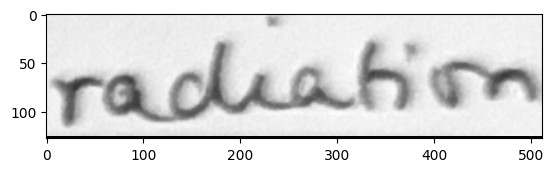

In [75]:
res = WordBox(prediction_groups[71])
DisplayWord(res)

In [76]:
word = res # This will be processed in the below code

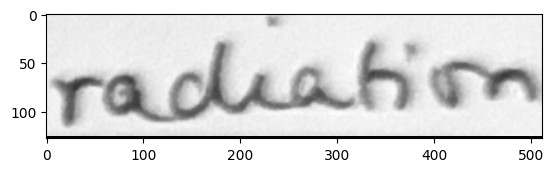

In [77]:
DisplayWord(word)

# Pre-processing

In [78]:
from skimage.morphology import medial_axis, skeletonize, thin

from skimage.util import invert
import skimage

Make the image black background on white

In [79]:
def BgChangeOptimised(word, CleaningCoefficient):

    # The higher the CleaningCoefficient, the more of the dimmer features that are cleaned out

    word = word * CleaningCoefficient

    word = tf.constant(np.where(word == 0, 1, word))

    word = tf.where(word > 1, 1, word)

    word = 1 - word

    # Below, we make the word brighter
    word = word * 1.5

    word = tf.where(word > 1, 1, word)

    DisplayWord(word)

    return tf.constant(word)
    

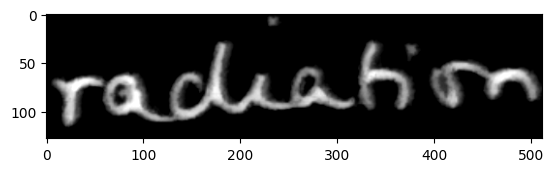

1.7197684


In [80]:
def ClCoeff(image):

    nonzero_indices = tf.where(tf.not_equal(tf.math.reduce_sum(image, axis=1), 0))
    first_nonzero_index = tf.reduce_min(nonzero_indices, axis=0)[0]
    last_nonzero_index = tf.reduce_max(nonzero_indices, axis=0)[0]

    return 1 / tf.math.reduce_mean(image[first_nonzero_index: last_nonzero_index])

image = BgChangeOptimised(word, ClCoeff(word))

tf.print(ClCoeff(word))

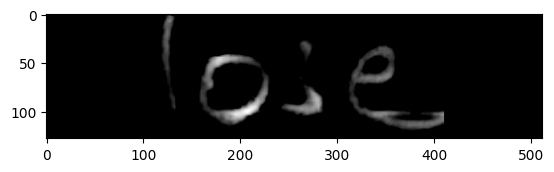

In [14]:
im2 = BgChangeOptimised(word, ClCoeff(word) * 1.5)

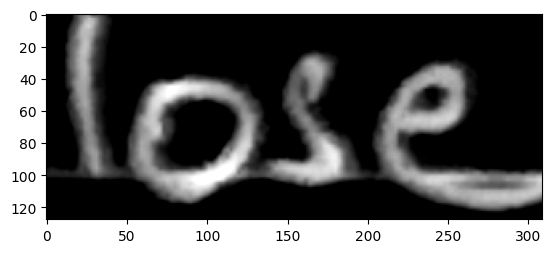

In [15]:
nonzero_indices = tf.where(tf.not_equal(tf.math.reduce_sum(word, axis=1), 0))
first_nonzero_index = tf.reduce_min(nonzero_indices, axis=0)[0]
last_nonzero_index = tf.reduce_max(nonzero_indices, axis=0)[0]

DisplayWord(image[first_nonzero_index: last_nonzero_index])


Remove Line 

In [16]:
thickness = 2
length = 200

In [17]:
image_new = tf.reshape(image, [image.shape[0], image.shape[1]])

In [18]:
image_cv = image_new.numpy()
# image_cv = image_cv.astype("uint8")
image_cv *= 256
image_cv = np.uint8(image_cv)
thresh = cv2.threshold(image_cv, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]

In [19]:
vertical_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (thickness,length))
remove_vertical = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, vertical_kernel, iterations=1)
cnts = cv2.findContours(remove_vertical, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = cnts[0] if len(cnts) == 2 else cnts[1]

In [20]:
word_cv = image_new.numpy()
word_cv *= 256
word_cv = np.uint8(word_cv)

In [21]:
for c in cnts:
    cv2.drawContours(word_cv, [c], -1, (255,255,255), thickness)

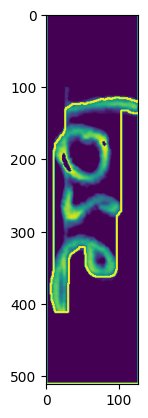

In [22]:
plt.imshow(word_cv)

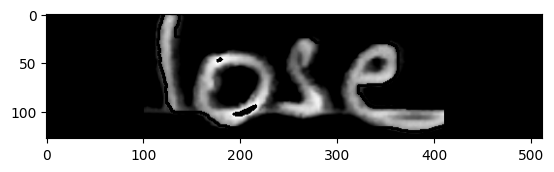

In [23]:
for c in cnts:
    cv2.drawContours(image_cv, [c], -1, (0,0,0), thickness)

image_changed = tf.constant(image_cv)
DisplayWord(image_changed)

Slope removal

In [24]:
def RotateImage(image, angle):
    image = tf.reshape(image, [image_width,image_height])
    im = image.numpy()
    im = Image.fromarray(im)
    im_rotated = im.rotate(angle=angle)
    im = np.asarray(im_rotated)
    image_r = tf.convert_to_tensor(im)

    return image_r

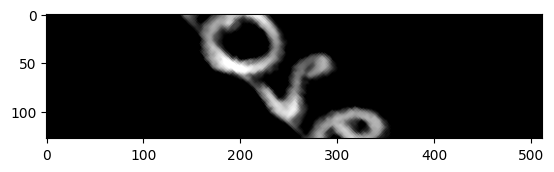

In [25]:
DisplayWord(RotateImage(image, -45))

In [26]:
# if tf.where(image[200] != 0).shape == (0,1):
#     print("empty")
# else:
#     print(tf.where(image[200] != 0)[-1][0].numpy())

In [27]:
def HorizontallHistorgram(image):
    image = tf.reshape(image, [image_width,image_height])
    image = tf.where(image != 0, 1, image)
    
    sums2 = tf.map_fn(lambda x: tf.math.reduce_sum(x), image)

    dists = [] # This stores the distance between the top and the bottom pixel

    for i in range(len(image)):
        non_zero = tf.where(image[i] != 0)
        
        if non_zero.shape == (0,1):
            dists.append(0)
        else:
            top = non_zero[0][0].numpy()
            bottom = non_zero[-1][0].numpy()
            dists.append(bottom - top + 1)

    dists = tf.constant(dists, dtype=tf.float32)

    Hw = tf.divide(sums2, dists)

    return tf.where(tf.math.logical_not(tf.math.is_finite(Hw)), tf.zeros_like(Hw), Hw)

    # return sums2, dists

In [28]:
def VerticalHistorgram(image):
    image = tf.reshape(image, [image_width,image_height])
    sums2 = tf.reduce_sum(image, axis=0)
    return sums2

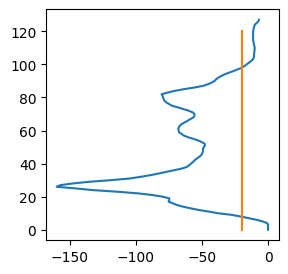

In [29]:
plt.figure(figsize=(3,3))
base = plt.gca().transData
rot = transforms.Affine2D().rotate_deg(90)

Vals = VerticalHistorgram(image)

plt.plot(Vals, transform = rot + base)

plt.plot([-20, -20], [-0, 120])

In [30]:
def GetVariance(Vals, threshold):
    below_threshold_mask = tf.math.less_equal(Vals, threshold)
    weight_below = tf.math.reduce_sum(tf.cast(below_threshold_mask, dtype=tf.float32))
    vals_below = tf.cast(below_threshold_mask, dtype=tf.float32) * Vals # These are the values below the threshold
    vals_below = tf.boolean_mask(vals_below, tf.math.logical_not(tf.math.equal(vals_below, 0))) # Remove the zeros
    variance_below_threshold = tf.math.reduce_variance(vals_below)

    above_threshold_mask = tf.math.greater(Vals, threshold)
    weight_above = tf.math.reduce_sum(tf.cast(above_threshold_mask, dtype=tf.float32))
    vals_above = tf.cast(above_threshold_mask, dtype=tf.float32) * Vals # These are the values above the threshold
    vals_above = tf.boolean_mask(vals_above, tf.math.logical_not(tf.math.equal(vals_above, 0))) # Remove the zeros
    variance_above_threshold = tf.math.reduce_variance(vals_above)

    weighted_variance = ( variance_above_threshold * weight_above + variance_below_threshold * weight_below ) / ( weight_above + weight_below )

    return weighted_variance

In [31]:
# Find the core region and the area of the image to be scanned

x = []
y = []

for i in range(5, int(tfp.stats.percentile(Vals, 90)), 1):
    x.append(i)

    y.append(GetVariance(Vals, i))

# plt.plot(x, y)

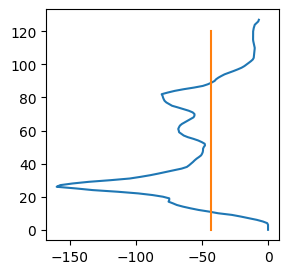

In [32]:
core_threshold = x[y.index(min(y))]

plt.figure(figsize=(3,3))
base = plt.gca().transData
rot = transforms.Affine2D().rotate_deg(90)

plt.plot(Vals, transform = rot + base)

plt.plot([-core_threshold, -core_threshold], [-0, 120])

In [33]:
above_threshold_mask = tf.math.greater(Vals, core_threshold)
locs = tf.where(above_threshold_mask)
core_region_base = int(locs[-1])
core_width = len(locs)

In [34]:
low_limit = int(core_region_base - 0.25 * core_width)
upper_limit = int(core_region_base + 0.25 * core_width)

In [35]:
# This attempts to find the bases of characters within the base character bounds
# This has significant run-time

base = []

for column in range(len(image)):
    found = False # To reset
    index = 0
    val_max = 0 # To reset

    for i in range(low_limit, upper_limit):
        # print(image[column][i])
        if image[column][i] != 0 and found == False:
            found = True
            if image[column][i] > val_max:
                index = i
                val_max = image[column][i]

        elif image[column][i] != 0 and found == True:
            if image[column][i] > val_max:
                index = i
                val_max = image[column][i]        

        elif image[column][i] == 0 and found == True:   
            found = False
            val_max = 0

    if image[column][upper_limit] == 0: # This prevents lines which extend below from being counted
        base.append(index)
    else:
        base.append(0)

print(base)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 105, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 103, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 68, 68, 68, 68, 68, 68, 68, 68, 68, 68, 68, 71, 71, 71, 75, 75, 77, 77, 77, 78, 78, 77, 78, 78, 78, 79, 80, 82, 82, 82, 80, 80, 80, 80, 82, 82, 82, 82, 82, 82, 82, 82, 82, 82, 82, 82, 80, 80, 80, 80, 80, 80, 80, 80, 80, 80, 79, 78, 77, 77, 76, 75, 75, 75, 75, 73, 71, 68, 68, 68, 68, 68, 68, 68, 70, 70, 68, 68, 68, 68, 68, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 70, 70, 71, 71, 75, 75, 75, 75, 75, 68, 68, 73, 72, 92, 94, 96, 96, 96, 96, 96, 96, 94, 94, 93, 92, 91, 92, 92, 93, 93, 94, 93, 96, 96, 96, 97, 97, 0, 0, 0, 0, 0, 0, 0, 0, 0

In [36]:
line = 0
found = False # To reset
index = 0
val_max = 0
val_max_list = []
val_max_indices = []

for i in range(len(base)):
    print(found)
    if base[i] != 0 and found == False:
        line += 1
        found = True
        if base[i] > val_max:
            index = i
            val_max = base[i]

    elif base[i] != 0 and found == True:
        if base[i] > val_max:
            index = i
            val_max = base[i]        

    elif base[i] == 0 and found == True:   
        found = False
        val_max_list.append(val_max)
        val_max_indices.append(index)
        val_max = 0

print(val_max_indices)
print(val_max_list)

val_max_indices = tf.reshape(tf.constant(val_max_indices), [len(val_max_indices),1])
val_max_list =  tf.reshape(tf.constant(val_max_list), [len(val_max_list),1])

False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
True
True
True
True
True
True
True
True
True
True
True


In [37]:
line = LinearRegression().fit(val_max_indices, val_max_list)

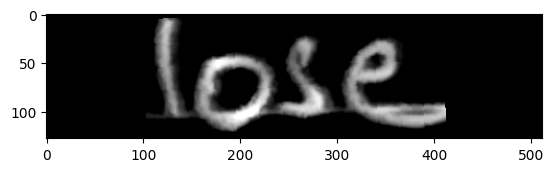

In [38]:
rotate = - math.atan(line.coef_[0][0]) * 180 / math.pi
image = RotateImage(image, rotate)
DisplayWord(image)

In [39]:
rotate

2.3632916163227353

Slant removal

In [40]:
# Investigate shearing but not used

def shear_image(image, angle):
    """
    Shear a TensorFlow image by a given angle.

    Parameters:
    - image: TensorFlow tensor, input image (batched or not)
    - angle: float, shear angle in radians

    Returns:
    - sheared_image: TensorFlow tensor, sheared image
    """
    # Get image shape
    image_shape = tf.shape(image)

    # Create shear matrix
    shear_matrix = tf.raw_ops.AffineWarpImage(
        images=tf.expand_dims(image, axis=0),  # Batch dimension
        transforms=tf.convert_to_tensor([[[np.cos(angle), -np.sin(angle), 0.0],
                                          [np.sin(angle), np.cos(angle), 0.0]]],
                                        dtype=tf.float32),
        output_shape=image_shape
    )

    # Extract the sheared image from the batch
    sheared_image = shear_matrix[0]

    return sheared_image

In [41]:
# Shear investigation function - this is not used

def ShearTest(image, InitAngle, reps):
    # When reps = 1, the function takes around 1.5 s to run

    scores = []

    image = tf.reshape(image, [image_width, image_height])
    image = tf.reshape(image, [1, image_width, image_height])

    shear = tf.keras.preprocessing.image.apply_affine_transform(image, theta = InitAngle, shear = -InitAngle)

    Hist = HorizontallHistorgram(shear)

    Score = tf.math.reduce_sum(tf.math.square(Hist))

    scores.append(Score)

    for i in range(reps):
        shear = tf.keras.preprocessing.image.apply_affine_transform(shear, theta = InitAngle, shear = -InitAngle)

        # DisplayWord(shear)
        
        Hist = HorizontallHistorgram(shear)

        # plt.plot(Hist)
        # plt.show()

        Score = tf.math.reduce_sum(tf.math.square(Hist))

        scores.append(Score)
    
    scores = tf.stack(scores)
    return scores


In [42]:
# Shear investigation function - this is where a lot of the run-time comes from

def ShearTest2(image, angle, reps):
    # When reps = 1, the function takes around 1.5 s to run

    scores = []

    image = tf.reshape(image, [image_width, image_height])
    image = tf.reshape(image, [1, image_width, image_height])

    for rep in range(reps):

        InitAngle = rep * angle

        print(InitAngle)

        shear = tf.keras.preprocessing.image.apply_affine_transform(image, theta = InitAngle, shear = -InitAngle)

        # DisplayWord(shear)
        
        Hist = HorizontallHistorgram(shear)

        # plt.plot(Hist)
        # plt.show()

        Score = tf.math.reduce_sum(tf.math.square(Hist))

        scores.append(Score)
    
    scores = tf.stack(scores)
    return scores


In [43]:
def GetShearAngle(image):
    rep = 20
    max_angle = 10

    angle = max_angle / rep

    positive = ShearTest2(image, angle, rep)
    negative = ShearTest2(image, - angle, rep)

    score = tf.concat([negative, positive], 0)

    sorted_indices = tf.argsort(score)
    index_min = sorted_indices[2].numpy()

    shear_angle = ( index_min - rep ) * angle

    print(f"Shear angle : {shear_angle}")

    return shear_angle

ShearAngle = GetShearAngle(image)

0.0
0.5
1.0
1.5
2.0
2.5
3.0
3.5
4.0
4.5
5.0
5.5
6.0
6.5
7.0
7.5
8.0
8.5
9.0
9.5
-0.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
-4.5
-5.0
-5.5
-6.0
-6.5
-7.0
-7.5
-8.0
-8.5
-9.0
-9.5
Shear angle : -1.5


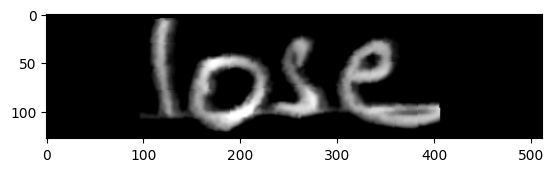

In [44]:
image = tf.reshape(image, [image_width, image_height])
image = tf.reshape(image, [1, image_width, image_height])

shear = tf.keras.preprocessing.image.apply_affine_transform(image, theta = ShearAngle, shear = - ShearAngle)

image = shear

image = tf.reshape(image, [image_width, image_height])

DisplayWord(image)

Make the characters 1 pixel wide

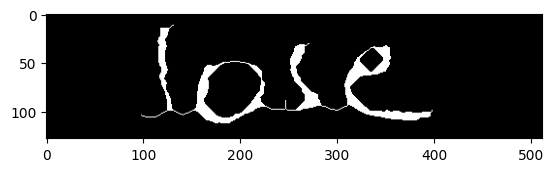

In [45]:
skeleton = thin(image, max_num_iter=10)

# or skeletonize(image)

DisplayWord(skeleton)

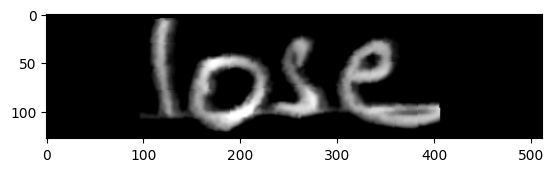

In [46]:
DisplayWord(image)

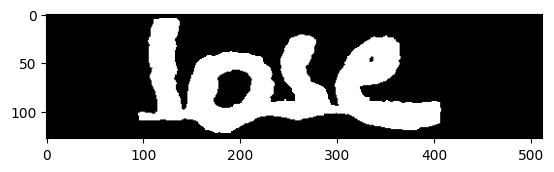

In [47]:
def convert_non_zero_to_one(tensor):
    # Create a boolean mask for non-zero values
    non_zero_mask = tf.math.not_equal(tensor, 0)
    
    # Convert non-zero values to 1 using the boolean mask
    result_tensor = tf.where(non_zero_mask, 1, tensor)
    
    return result_tensor

DisplayWord(convert_non_zero_to_one(image))

In [48]:
def SoftenImage(word, CleaningIndex):
    # CleaningIndex is a value from 0 to 10. Higher the value, the more of the high stress areas will be highlighted.


    word = tf.constant(np.where(word < CleaningIndex / 10, 0, word))

    return tf.constant(word)

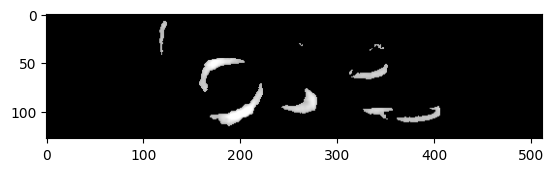

In [49]:
DisplayWord(SoftenImage(image, 7))

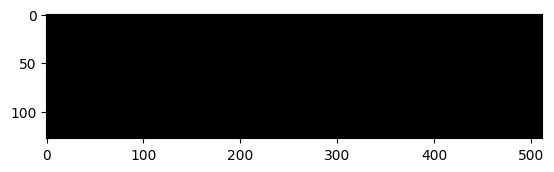

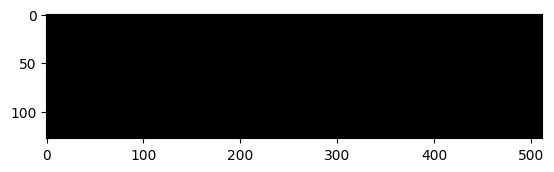

In [50]:
DisplayWord(BgChangeOptimised(word, 11))

# Charcter segmentation

In [81]:
# All this is for the purpose of visualising the points at which the breaks needed to be drawn

def DrawVertical(x_position, image):

    height, width = image.shape
    mask = tf.zeros_like(image)
    mask = tf.concat([image[:x_position, :], tf.ones([1, width]), image[x_position+1:, :]], axis=0)  # White vertical line

    return mask

def DrawBoundaries(positions, image):
    LinedImg = DrawVertical(positions[0], image)

    for i in range(1, len(positions)):
        LinedImg = DrawVertical(positions[i], LinedImg)

    DisplayWord(LinedImg)

    return LinedImg


In [82]:
image = tf.reshape(image, [image.shape[0], image.shape[1]])

TempImg = tf.math.square(image)

sums = tf.reduce_sum(TempImg, axis=1)
positions = tf.range(0, image_width, dtype=tf.float32)

NewSegment = tf.Variable(256)

Here we use a decision tree approach

In [83]:
def LossFnTree(begin, end, split):

    local_segments = [split, end]

    VarTotal = 0

    prev = begin

    Averages = []

    for i in range(len(local_segments)):

        Avg = tf.math.reduce_sum(tf.math.multiply(sums[prev:local_segments[i]], positions[prev:local_segments[i]])) / tf.math.reduce_sum(sums[prev:local_segments[i]])

        VarTotal += tf.math.sqrt(tf.math.reduce_sum(tf.math.multiply(tf.math.square(positions[prev:local_segments[i]] - Avg), sums[prev:local_segments[i]])) / tf.math.reduce_sum(sums[prev:local_segments[i]]))

        Averages.append(Avg)

        prev = local_segments[i]

    if math.isnan(VarTotal.numpy()):
        loss0 = 0
    else:
        loss0 = VarTotal.numpy()

    if math.isnan(tf.math.reduce_variance(tf.stack(Averages)).numpy()):
        loss1 = 0
    else:
        loss1 = tf.math.reduce_variance(tf.stack(Averages)).numpy()

    if math.isnan(abs((end - split) - (split - begin))):
        loss2 = 0
    else:
        loss2 = abs((end - split) - (split - begin))

    return [loss0, loss1, loss2]

In [84]:
def Normalise(l, m): # Get the value to between 1 and m
    factor = max(l) / m

    try:
        return [ e/factor for e in l]
    except ZeroDivisionError:
        return l

In [85]:
def TreeSegmentation(segments, threshold):    
    # Threshold is the width of a segment according to the list segments
    differences = [segments[i + 1] - segments[i] for i in range(len(segments) - 1)]

    while True:

        if sum([True if j < threshold else False for j in differences]) == 1:
            index = -2
        elif sum([True if j < threshold else False for j in differences]) == 0:
            index = 0
        else:
            break

        begin = segments[index]
        end = segments[index + 1]

        losses = []

        for split in range(begin, end):
            losses.append(LossFnTree(begin, end, split))

        loss0 = [i[0] for i in losses]
        loss1 = [i[1] for i in losses]
        loss2 = [i[2] for i in losses]

        loss0 = Normalise(loss0, 10)
        loss1 = Normalise(loss1, 15)
        loss2 = Normalise(loss2, 5)

        losses = [ loss0[i] - loss1[i] + loss2[i] for i in range(len(losses))]

        # plt.plot(losses)
        # plt.show()

        segments.append(losses.index(min(losses)) + begin)

        segments.sort()

        print(segments)

        differences = [segments[i + 1] - segments[i] for i in range(len(segments) - 1)]

    DrawBoundaries(segments, image)

    return segments, differences

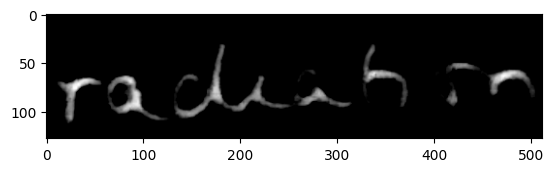

In [86]:
# This draws a boundary in the middle of the blank spaces between characters

im2 = BgChangeOptimised(word, ClCoeff(word) * 1.5)
""" The same tranformations that were applied to 'image' need to be applied to be 'word' so that the new image generated is also compatible"""
im2 = tf.reshape(im2, [im2.shape[0], im2.shape[1]])
sums2 = tf.reduce_sum(tf.math.square(im2), axis=1)

segments = [tf.argmax(tf.cast(tf.not_equal(sums2, 0), tf.int32), output_type=tf.int32).numpy(), image_width - tf.argmax(tf.cast(tf.not_equal(tf.reverse(sums2, axis=[0]), 0), tf.int32), output_type=tf.int32).numpy()]

started = False

for i in range(tf.argmax(tf.cast(tf.not_equal(sums2, 0), tf.int32), output_type=tf.int32).numpy() + 1, image_width - tf.argmax(tf.cast(tf.not_equal(tf.reverse(sums2, axis=[0]), 0), tf.int32), output_type=tf.int32).numpy()):
    if sums2[i] == 0 and not started:
        start = i
        started = True
    elif sums2[i] != 0 and sums2[i - 1] == 0:
        end = i
        segments.append(int((start + end) / 2))
        started = False

segments.sort()

differences = [segments[i + 1] - segments[i] for i in range(len(segments) - 1)]

[60, 126, 127]
[60, 126, 126, 127]


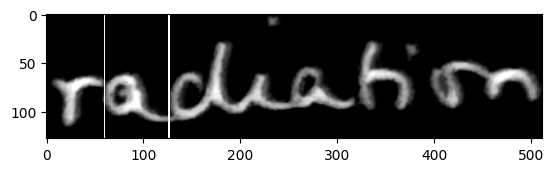

[130, 237, 321]
[130, 195, 237, 321]
[130, 195, 237, 320, 321]


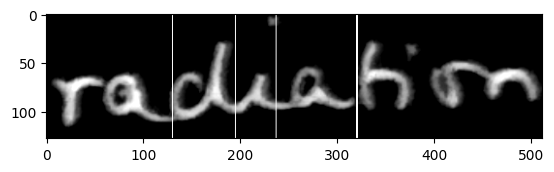

[321, 386, 388]
[321, 386, 387, 388]


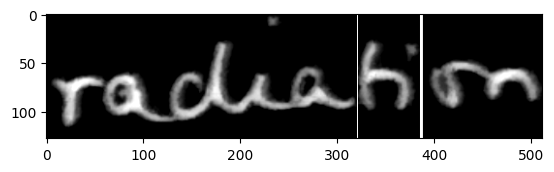

[411, 452, 505]
[411, 452, 484, 505]


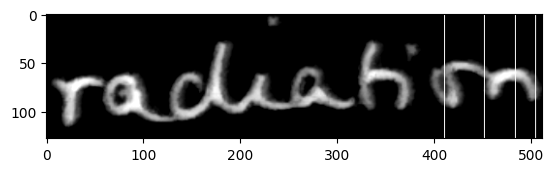

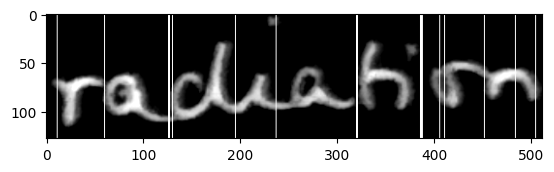

<tf.Tensor: shape=(512, 128), dtype=float32, numpy=
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)>

In [87]:
avg_diff = sum(differences) / ( len(differences) + 2 )

new_segments = []

for i in range(len(differences)):
    if differences[i] > avg_diff:
        n, d = TreeSegmentation([segments[i], segments[i + 1]], threshold = avg_diff)
        new_segments += n

boundaries = list(set(new_segments + segments))

DrawBoundaries(boundaries, image)

In [88]:
boundaries.sort()
left = min(boundaries)
new_image = image[left:max(boundaries)]
boundaries = [i - left for i in boundaries]

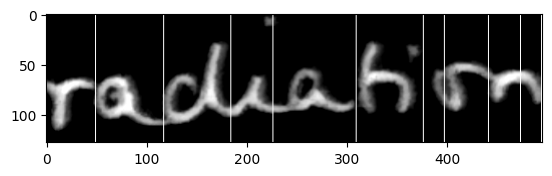

<tf.Tensor: shape=(495, 128), dtype=float32, numpy=
array([[1., 1., 1., ..., 1., 1., 1.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 1., 1., ..., 1., 1., 1.]], dtype=float32)>

In [89]:
final_boundaries = [0]

for i in range(len(boundaries) - 1):
    if abs(boundaries[i] - boundaries[i + 1]) > 5:
        final_boundaries.append(boundaries[i + 1])
    else:
        final_boundaries[-1] = int((boundaries[i] + boundaries[i+1]) / 2 )

boundaries = final_boundaries

DrawBoundaries(final_boundaries, new_image)

In [ ]:
# # This adjusts the image based on the number of characters expected to be in the word

# label = "lose"

# if ( len(boundaries) - 1 ) < len(label):
#     # This is case of undersegmentation
#     while ( len(boundaries) - 1 ) != len(label):
#         diff_max = 0
#         diff_max_i = 0
#         for i in range(len(boundaries) - 1):
#             if (boundaries[i + 1] - boundaries[i]) > diff_max:
#                 diff_max = boundaries[i + 1] - boundaries[i]
#                 diff_max_i = i

#         boundaries.insert(i+1, int((boundaries[i + 1] + boundaries[i])/2))

# elif ( len(boundaries) - 1 ) > len(label):
#     # This is the case of undersegmentation
#     while ( len(boundaries) - 1 ) != len(label):
#         sum_min = image_width
#         sum_min_i = 0
#         for i in range(len(boundaries) - 1):
#             if (boundaries[i + 1] - boundaries[i]) < sum_min:
#                 sum_min = boundaries[i + 1] - boundaries[i]
#                 sum_min_i = i

#         if (boundaries[sum_min_i + 1] - boundaries[sum_min_i - 1]) < (boundaries[sum_min_i + 2] - boundaries[sum_min_i]):
#             boundaries.pop(sum_min_i)
#         else:
#             boundaries.pop(sum_min_i + 1)
    

# DrawBoundaries(boundaries, new_image)

In [61]:
width = - ( tf.argmax(tf.cast(tf.not_equal(sums, 0), tf.int32), output_type=tf.int32).numpy() - (image_width - tf.argmax(tf.cast(tf.not_equal(tf.reverse(sums, axis=[0]), 0), tf.int32), output_type=tf.int32).numpy()) )

v_sums = tf.reduce_sum(new_image, axis=0)
non_zero_indices = tf.where(v_sums != 0)
height = (non_zero_indices[-1][0] - non_zero_indices[0][0]).numpy()

print("Height = ", height, " Width = ", width)
print("Ratio : ", width / height, " Letters : ", len(label))

Height =  117  Width =  313
Ratio :  2.675213675213675  Letters :  5


Remove line

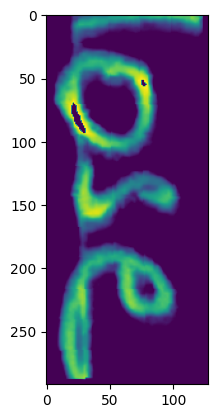

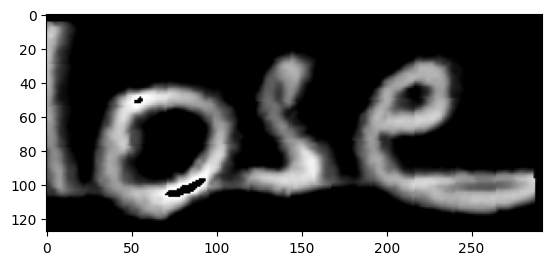

In [62]:
thickness = 1
length = image.shape[0] - 10

image_new = tf.reshape(image, [image.shape[0], image.shape[1]])

image_cv = image_new.numpy()
# image_cv = image_cv.astype("uint8")
image_cv *= 256
image_cv = np.uint8(image_cv)
# thresh = cv2.threshold(image_cv, 0.1, 1, cv2.THRESH_BINARY)[1]
thresh = cv2.threshold(image_cv, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

vertical_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (thickness,length))
remove_vertical = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, vertical_kernel, iterations=1)
cnts = cv2.findContours(remove_vertical, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = cnts[0] if len(cnts) == 2 else cnts[1]

word_cv = image_new.numpy()
word_cv *= 256
word_cv = np.uint8(word_cv)

# This code shows the effect of the removal algo

for c in cnts:
    cv2.drawContours(word_cv, [c], -1, (255,255,255), thickness)

plt.imshow(word_cv)
plt.show()

# The code showing the effect of the removal algorithm ends here

for c in cnts:
    cv2.drawContours(image_cv, [c], -1, (0,0,0), thickness)

image_changed = tf.constant(image_cv)
DisplayWord(image_changed)

Character blocks

In [96]:
def pad_image(image, target_height, target_width):
    image = image[:,tf.where(tf.reduce_sum(image, axis=0))[0][0]:tf.where(tf.reduce_sum(image, axis=0))[-1][0]]

    # Get the current dimensions of the image
    height, width = tf.shape(image)[0], tf.shape(image)[1]

    # Calculate the amount of padding needed
    pad_height = tf.maximum(128 - height, 0)
    pad_width = tf.maximum(128 - width, 0)

    # Calculate the amount of padding on each side
    top_pad = pad_height // 2
    bottom_pad = pad_height - top_pad
    left_pad = pad_width // 2
    right_pad = pad_width - left_pad

    # Pad the image
    padded_image = tf.pad(image, [[top_pad, bottom_pad], [left_pad, right_pad]], mode='CONSTANT', constant_values=0)

    return tf.image.resize(tf.reshape(padded_image, [padded_image.shape[0], padded_image.shape[1], 1]), [target_height, target_width])

In [98]:
characters = []

for i in range(len(boundaries) - 1):
    if abs(boundaries[i] - boundaries[i + 1]) > 3:
        char = new_image[boundaries[i]: boundaries[i + 1]]
        print(char.shape)
        characters.append(pad_image(char, 128, 128))

(49, 128)
(68, 128)
(67, 128)
(42, 128)
(83, 128)
(67, 128)
(21, 128)
(44, 128)
(32, 128)
(21, 128)


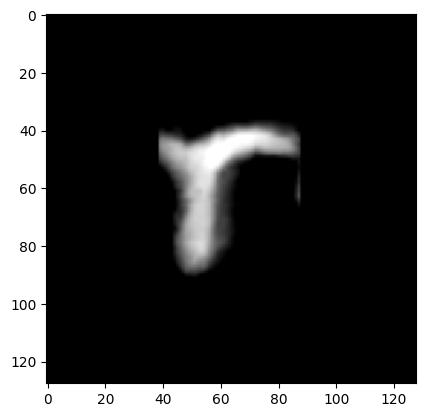

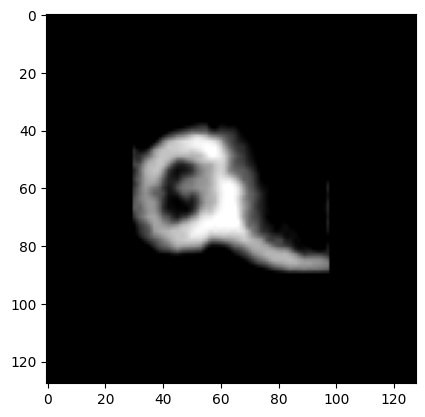

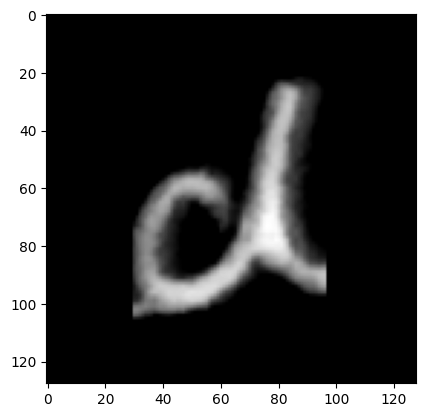

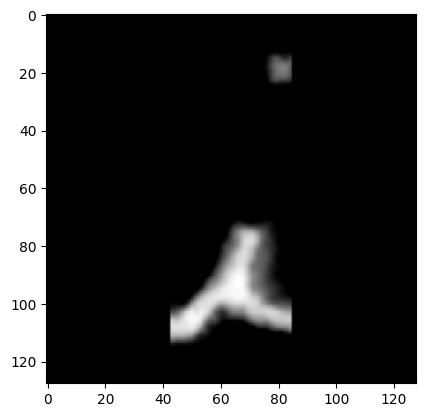

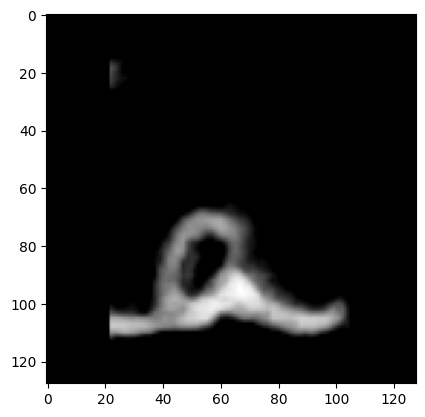

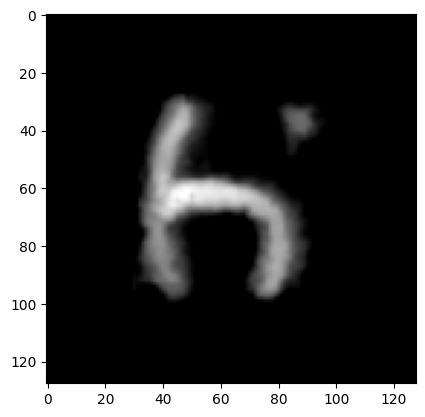

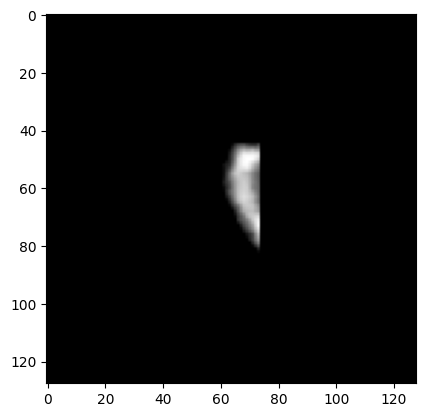

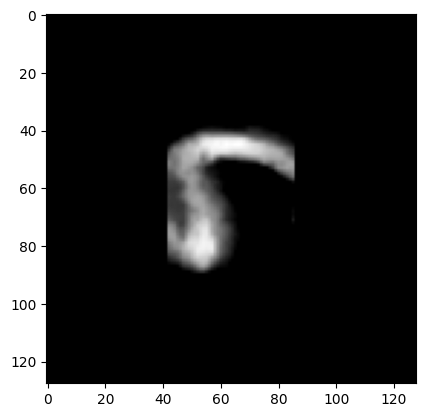

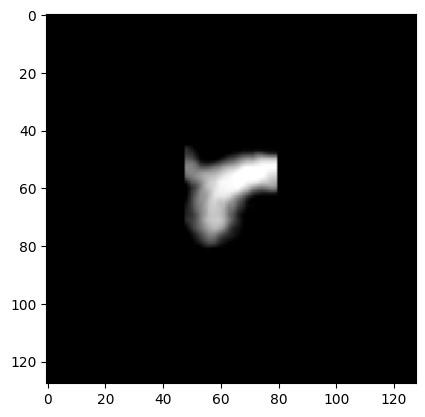

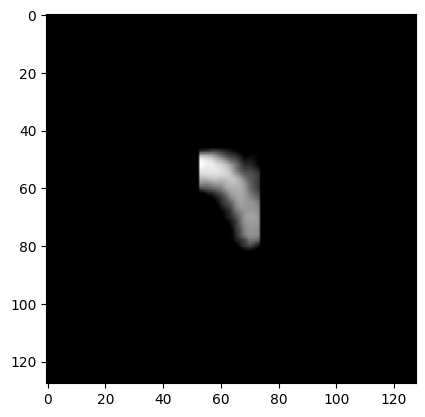

In [99]:
for i in characters:
    DisplayWord(i)